# LiteMedSAM: one-image local walkthrough
Official ultrasound demonstration, pretrained weights, supplied box. This checks software execution; it does not measure clinical accuracy.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if not (ROOT/'scripts').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
import numpy as np
import matplotlib.pyplot as plt
import torch
from run_litemedsam import run
print('PyTorch:',torch.__version__)
print('Device: CPU; MPS available:',torch.backends.mps.is_available())

PyTorch: 2.6.0
Device: CPU; MPS available: True


/Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Result/inference:** The printed version identifies the installed runtime. This notebook deliberately uses CPU; MPS availability does not mean MPS was tested.

Image: (420, 580, 3) uint8 Box xyxy: [265, 78, 347, 196]


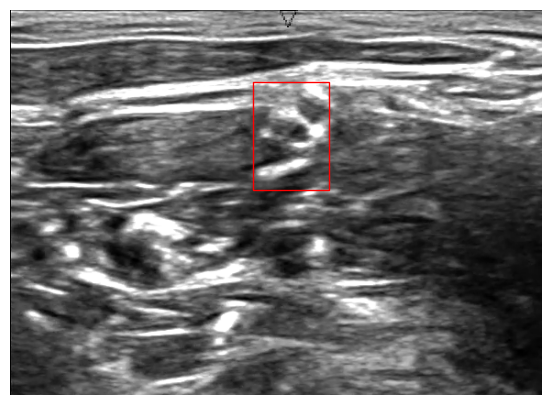

In [2]:
sample=np.load(ROOT/'demo/imgs/2DBox_US_demo.npz',allow_pickle=False)
image=sample['imgs']; box=sample['boxes'][0]
print('Image:',image.shape,image.dtype,'Box xyxy:',box.tolist())
plt.figure(figsize=(7,5)); plt.imshow(image)
from matplotlib.patches import Rectangle
plt.gca().add_patch(Rectangle(box[:2],box[2]-box[0],box[3]-box[1],fill=False,edgecolor='red'))
plt.axis('off'); plt.show()

**Result/inference:** The authors provide one box for this 420 x 580 RGB demonstration. The box supplies a region prompt; the model does not find it autonomously.

In [3]:
report=run(image,box,ROOT/'checkpoints/lite_medsam.pth',ROOT/'outputs/notebook_demo')
print(json.dumps(report,indent=2))

{
  "device": "cpu",
  "image_shape": [
    420,
    580,
    3
  ],
  "box_xyxy": [
    265.0,
    78.0,
    347.0,
    196.0
  ],
  "input_tensor": [
    1,
    3,
    256,
    256
  ],
  "image_embedding": [
    1,
    256,
    64,
    64
  ],
  "sparse_prompt": [
    1,
    2,
    256
  ],
  "dense_prompt": [
    1,
    256,
    64,
    64
  ],
  "mask_logits": [
    1,
    1,
    256,
    256
  ],
  "mask_shape": [
    420,
    580
  ],
  "foreground_pixels": 4990,
  "predicted_mask_quality": 0.8367437720298767,
  "inference_seconds_excludes_loading_and_preprocessing": 0.42604433400265407,
  "checkpoint_sha256": "79d8c9dca6db4d69d3f905579e5250af05e859fff9c1f543e89a513c3028ce76",
  "note": "Execution check only. Predicted quality is not measured IoU or diagnostic confidence."
}


**Result/inference:** Strict checkpoint loading and finite-output assertions must pass. The printed shapes trace the image and prompt into mask logits. Timing excludes model loading and preprocessing. Predicted mask quality is not measured IoU.

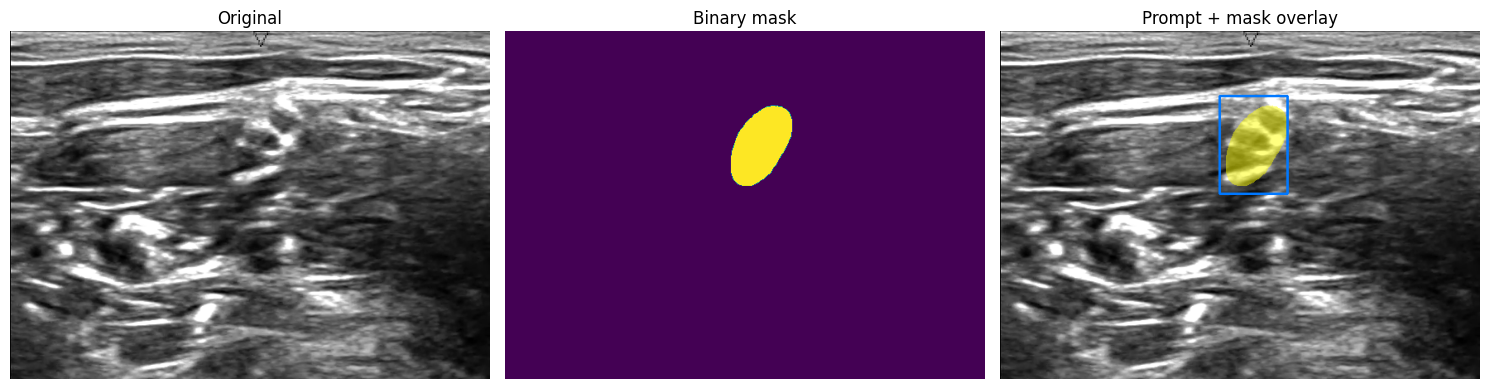

Saved mask: /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/outputs/notebook_demo/mask.png


In [4]:
from PIL import Image
fig,axes=plt.subplots(1,3,figsize=(15,5))
for ax,name,title in zip(axes,['image.png','mask.png','overlay.png'],['Original','Binary mask','Prompt + mask overlay']):
    ax.imshow(Image.open(ROOT/'outputs/notebook_demo'/name)); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()
print('Saved mask:',ROOT/'outputs/notebook_demo/mask.png')

**Result/inference:** These files establish the image + box -> saved mask pass check. Visual plausibility is not accuracy validation. Next, read the small runner and study guide, then follow the upstream source index. MedNet and integration are separate pending work.